# Analyse Exploratoire de Données (EDA) — Ressources Humaines

**Contexte :** ce projet porte sur 5 sources de données internes d'une entreprise :
* `emp_data.xlsx` — fiches des **1461 employés techniques** (informatique, télécom, communication) ;
* `administration_data.xlsx` — fiches des **1279 agents administratifs** ;
* `attendance_dataset_2023.csv` — **pointages** des employés techniques (janv. → juin 2023) ;
* `Administration_attendance.xlsx` — **pointages** des agents administratifs (janv. → mars 2023) ;
* `Coursera_trainings.csv` — **catalogue** de 3 532 formations en ligne ;
* `departments.ods` + `extrainfos.txt` — référentiel des départements et grille de coûts (vacataire 35 €/h, heures sup permanent 25 €/h, admin 22 €/h).

**Objectifs métier (OM) :**
* **OM1 — Pilotage des effectifs** : répartition et occupation des postes par département vs capacité, mix contractuel et tenure.
* **OM2 — Rémunération et masse salariale** : distribution des salaires, équité H/F, estimation de la masse salariale (y c. heures sup).
* **OM3 — Assiduité et temps de travail** : heures réellement travaillées, retards, absences, heures supplémentaires, comparaison équipes techniques / administration.
* **OM4 — Formation et compétences** : couverture de la formation, volume suivi, adéquation avec les difficultés/compétences du catalogue, recommandations par pôle.
* **OM5 — Congés et risque de départ** : consommation des congés, types de congé consommés, signaux de risque (fin de contrat CDD, tenure, solde).

*Les KPIs associés sont calculés et résumés dans la dernière section.*

In [1]:
# ============================================================================
# 0. Import, paramètres, chargement (avec cache intermédiaire)
# ============================================================================
import ast
import os
import pickle
import sys
import time as _t
import warnings

import matplotlib

def _in_notebook():
    try:
        from IPython import get_ipython
        return get_ipython() is not None
    except Exception:
        return False

if not _in_notebook():
    matplotlib.use("Agg")  # backend sans fenêtre (exécution en script)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

try:
    sys.stdout.reconfigure(line_buffering=True)
except (AttributeError, OSError):
    pass
_START = _t.time()


def _log(*a):
    print(f"[{_t.time() - _START:6.1f}s]", *a, flush=True)


warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"
os.makedirs("figures", exist_ok=True)

# Taux de coût (extrainfos.txt)
RATE_VACATAIRE = 35      # €/h
RATE_OT_PERM = 25        # €/h heures sup "permanent"
RATE_OT_ADMIN = 22       # €/h heures sup "admin"

DEP_LABEL = {"DEP_INF00": "Informatique", "DEP_TEL00": "Télécom",
             "DEP_COM01": "Communication", "DEP_ADMIN00": "Administration"}
DEP_ORDER_TECH = ["Informatique", "Télécom", "Communication"]
DEP_ORDER_ALL = DEP_ORDER_TECH + ["Administration"]

# Mode segmenté : `python eda.py --seg 1 --seg 3` exécute seulement les segments
args = [a for a in sys.argv[1:]]
run_all = "--seg" not in args
requested = {int(args[i + 1]) for i in range(len(args)) if args[i] == "--seg"}


def should(n):
    return run_all or n in requested


CACHE = "eda_cache.pkl"


def prep_data():
    """Charge les sources et prépare les tables (mise en cache binaire)."""
    emp = pd.read_excel("emp_data.xlsx").rename(columns={"CODE": "ID_Employee"})
    adm = pd.read_excel("administration_data.xlsx")
    att = pd.read_csv("attendance_dataset_2023.csv")
    att_a = pd.read_excel("Administration_attendance.xlsx")
    dep = pd.read_excel("departments.ods")
    cour = pd.read_csv("Coursera_trainings.csv")

    emp["DEP_LIB"] = emp["DEP_ID"].map(DEP_LABEL)
    adm["DEP_LIB"] = "Administration"
    adm["POSITION"] = "Administration"

    # Normalisation des libellés : "Sick" / "sick", "Free Application" / "free_application"
    emp["LEAVE_TYPE"] = emp["LEAVE_TYPE"].str.strip().str.lower()
    adm["LAST_LEAVE_TYPE"] = adm["LAST_LEAVE_TYPE"].str.strip().str.lower()
    for df in (emp, adm):
        df["SOURCE_of_employment"] = (df["SOURCE_of_employment"].str.strip()
                                      .str.lower().str.replace(" ", "_"))

    def prep(att_df):
        df = att_df.copy()
        df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
        for c in ["StartTime", "BreakTime", "ResumeTime", "EndTime"]:
            raw = df[c].astype(str).str.strip()
            x = pd.to_datetime(raw, format="%H:%M:%S", errors="coerce")
            x = x.fillna(pd.to_datetime(raw, format="%H:%M", errors="coerce"))
            df[c] = x
        df["worked"] = ((df["EndTime"] - df["StartTime"]) -
                        (df["ResumeTime"] - df["BreakTime"])) / pd.Timedelta(hours=1)
        df["late"] = df["StartTime"] > pd.to_datetime("08:30", format="%H:%M")
        df["ot"] = df["worked"] > 8
        return df

    att_p = prep(att)
    att_a_p = prep(att_a)
    return dict(emp=emp, adm=adm, att=att, att_a=att_a, dep=dep, cour=cour,
                att_p=att_p, att_a_p=att_a_p, _version=CACHE_VERSION)


# Le cache est reconstruit s'il est illisible (autre version de pandas) ou périmé
CACHE_VERSION = 2
DATA = None
if os.path.exists(CACHE):
    try:
        with open(CACHE, "rb") as f:
            DATA = pickle.load(f)
        if DATA.get("_version") != CACHE_VERSION:
            DATA = None
    except Exception as e:
        _log(f"cache illisible ({type(e).__name__}) : reconstruction")
        DATA = None
if DATA is None:
    DATA = prep_data()
    with open(CACHE, "wb") as f:
        pickle.dump(DATA, f)
_log("sources prêtes")

[   0.0s] cache illisible (TypeError) : reconstruction


[  12.2s] sources prêtes


## 1. Qualité des données et clés de jointure

La structure relationnelle est simple :

| Table | Clé | Lien |
|---|---|---|
| `emp_data` | `ID_Employee` | 1460/1461 retrouvés dans `attendance_dataset_2023` |
| `administration_data` | `ID_Employee` | 1279/1280 retrouvés dans `Administration_attendance` |
| `departments` | `ID_DEP` ↔ `DEP_ID` | 4 départements dont 1 administratif |
| `emp_data.ID_TRAINING` | liste d'ids → `Coursera_trainings.course_id` | couverture quasi-totale |

Points de vigilance constatés (à traiter dans l'EDA) :
* 1 agent administratif absent de la table des fiches (id orphelin : `d1f3417f-….`, à vérifier) ;
* `SALARY` / `HOURS` manquants selon le statut : un `Permanent` a un salaire, un `Vacataire` un volume d'heures — le coût se reconstitue avec la grille `extrainfos.txt` ;
* horaires admin au format `HH:MM` (sans secondes) → normalisation nécessaire ;
* aucune ligne dupliquée sur `(ID_Employee, Date)` dans les pointages.

In [2]:
if should(1):
    emp, adm, att, att_a, dep, cour, att_p, att_a_p = (_ for _ in [None] * 8)
    for name in ["emp", "adm", "att", "att_a", "dep", "cour", "att_p", "att_a_p"]:
        globals()[name] = DATA[name]

    print("Sources :",
          f"emp={emp.shape} adm={adm.shape} att={att.shape}",
          f"att_admin={att_a.shape} catalogue={cour.shape} dep={dep.shape}")
    print("ORPHELIN pointage admin sans fiche :", set(att_a.ID_Employee) - set(adm.ID_Employee))

    for name, df in [("emp", emp), ("adm", adm), ("att", att), ("att_a", att_a)]:
        print(f"\n[{name}] ID uniques: {df.ID_Employee.nunique()} | "
              f"lignes répétées (multi-jours) : {df.duplicated('ID_Employee').sum()}")

    print("\n=== MANQUANTS (en %) — emp_data ===")
    print((emp.isna().mean() * 100).sort_values(ascending=False).round(2).to_string())
    print("\n=== MANQUANTS SALARY/HOURS par statut ===")
    print(emp.groupby("POSITION")[["SALARY", "HOURS"]]
          .apply(lambda g: g.isna().mean().round(3)).to_string())
    print("\n=== MANQUANTS (en %) — administration ===")
    print((adm.isna().mean() * 100).sort_values(ascending=False).round(2).to_string())
    print("\n=== GENDER / MARITAL_STATUS ===")
    print(pd.DataFrame({"emp": emp.GENDER.value_counts(),
                        "adm": adm.GENDER.value_counts()}).to_string())
    print("MARITAL (emp):", emp.MARITAL_STATUS.value_counts().to_dict())
    _log("segment 1 — qualité OK")

Sources : emp=(1461, 31) adm=(1279, 25) att=(189799, 6) att_admin=(83200, 6) catalogue=(3532, 9) dep=(4, 3)
ORPHELIN pointage admin sans fiche : {'d1f3417f-6a3e-4a2d-92eb-cc768822f4f4'}

[emp] ID uniques: 1461 | lignes répétées (multi-jours) : 0

[adm] ID uniques: 1279 | lignes répétées (multi-jours) : 0

[att] ID uniques: 1460 | lignes répétées (multi-jours) : 188339

[att_a] ID uniques: 1280 | lignes répétées (multi-jours) : 81920

=== MANQUANTS (en %) — emp_data ===
ADRESSE_MISSION         64.61
HOURS                   50.92
CONTRACT_END            49.28
SALARY                  49.08
ID_TRAINING              1.37
STARTING_DATE            0.48
ADRESS                   0.48
LEAVE_CONSUMED           0.41
TECHNOLOGIES             0.34
DEP_ID                   0.27
DEP_LIB                  0.27
GRAD_UNIVERSITY          0.27
EMAIL                    0.27
LANGUAGE                 0.21
NAME_EMP                 0.21
ACTIVITY                 0.14
TYPE_CONTRACT            0.14
REGISTRATION_NUM

## 2. OM1 — Pilotage des effectifs et de la charge

**Interrogation métier :** l'effectif embarqué est-il cohérent avec la capacité des départements ?
Quels profils (contrat, activité, genre, tenure) ?

**KPIs :** taux d'occupation (effectif / capacité), part des contrats courts (CDD + CIVP),
répartition genre, ancienneté.

=== EFFECTIF VS CAPACITÉ ===
       DEP_LIB  effectif  CAPACITY  taux_occupation
Administration      1279       200            639.5
       Télécom       441       300            147.0
  Informatique       505       601             84.0
 Communication       511      1262             40.5


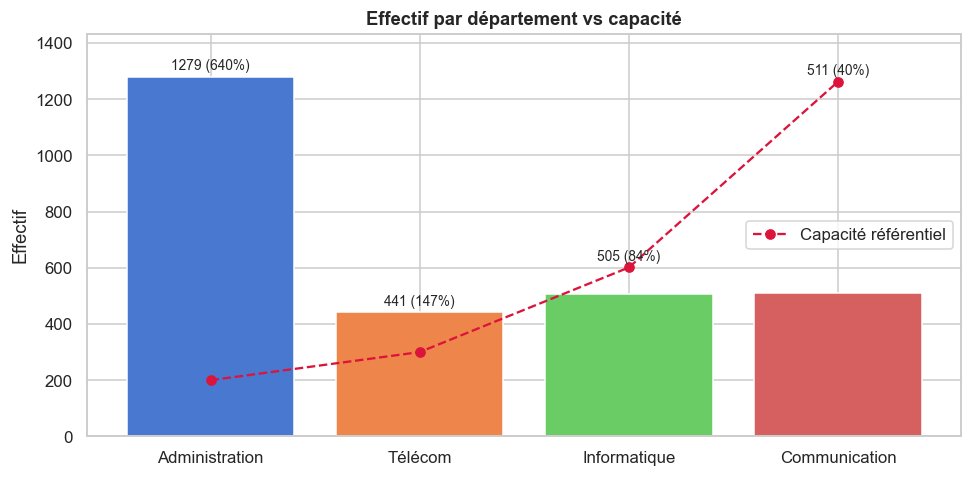


=== TYPE_DE_CONTRAT / ACTIVITY (emp) ===
TYPE_CONTRACT
CDD     490
CDI     485
CIVP    484
NaN       2
ACTIVITY
Mission      516
Technical    484
Research     459
NaN            2

=== CONTRAT × DÉPARTEMENT (%) ===
TYPE_CONTRACT   CDD   CDI  CIVP
DEP_LIB                        
Communication  31.9  35.4  32.7
Informatique   35.7  30.0  34.3
Télécom        33.2  34.3  32.5

=== TENURE (0 = <1 an, 1 = >=1 an) ===
{1: 741, 0: 720}

=== SOURCE DE RECRUTEMENT (emp / admin) ===
SOURCE_of_employment
free_application       448
recruitment_session    421
recommendation         418
ex-vacataire           174
SOURCE_of_employment
recommendation         461
recruitment_session    435
free_application       383


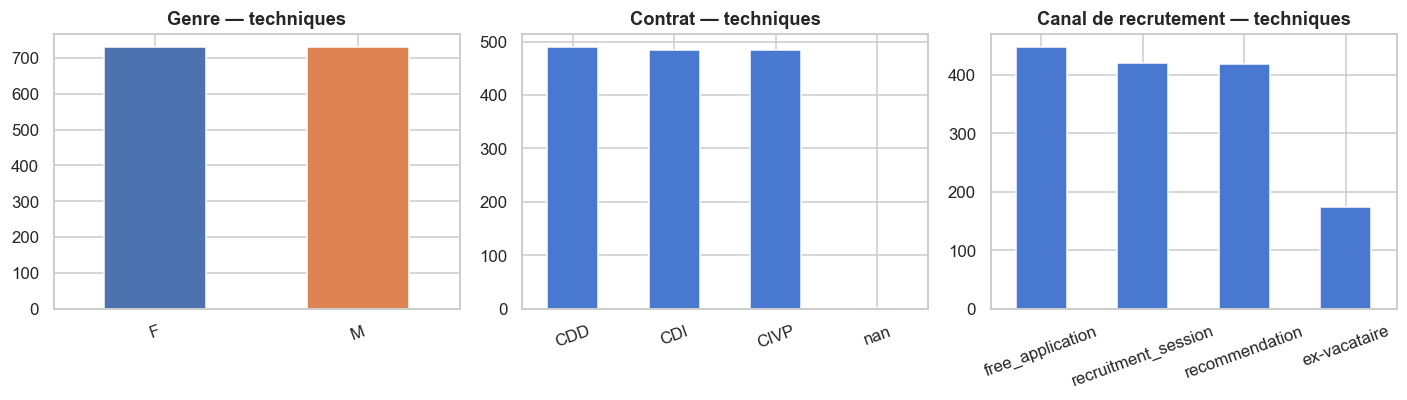

[  14.1s] segment 2 — OM1 OK


In [3]:
if should(2):
    emp, dep = DATA["emp"], DATA["dep"]

    # Effectif technique + administratif, rapproché de la capacité du référentiel
    eff_dep = pd.concat([emp[["DEP_ID"]], DATA["adm"][["DEP_ID"]]]).dropna()
    occ = (eff_dep.groupby("DEP_ID").size().rename("effectif").reset_index()
           .merge(dep.rename(columns={"ID_DEP": "DEP_ID"})[["DEP_ID", "CAPACITY"]],
                  on="DEP_ID", how="outer"))
    occ["DEP_LIB"] = occ.DEP_ID.map(DEP_LABEL)
    occ["taux_occupation"] = occ.effectif / occ.CAPACITY * 100
    occ = occ.sort_values("taux_occupation", ascending=False).reset_index(drop=True)
    print("=== EFFECTIF VS CAPACITÉ ===")
    print(occ[["DEP_LIB", "effectif", "CAPACITY", "taux_occupation"]].round(1).to_string(index=False))

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.bar(occ.DEP_LIB, occ.effectif, color=sns.color_palette("muted", len(occ)))
    ax.plot(range(len(occ)), occ.CAPACITY, "o--", color="crimson", label="Capacité référentiel")
    for i, row in occ.iterrows():  # index remis à 0..n-1 : l'étiquette tombe sur sa barre
        ax.annotate(f"{row.effectif:.0f} ({row.taux_occupation:.0f}%)",
                    (i, max(row.effectif, row.CAPACITY) + 25), ha="center", fontsize=9)
    ax.set_ylim(0, occ[["effectif", "CAPACITY"]].max().max() * 1.12)
    ax.set_ylabel("Effectif"); ax.set_title("Effectif par département vs capacité"); ax.legend()
    plt.tight_layout(); plt.savefig("figures/fig01_effectifs_capacite.png", bbox_inches="tight")
    plt.show()

    print("\n=== TYPE_DE_CONTRAT / ACTIVITY (emp) ===")
    print(emp.TYPE_CONTRACT.value_counts(dropna=False).to_string())
    print(emp.ACTIVITY.value_counts(dropna=False).to_string())
    print("\n=== CONTRAT × DÉPARTEMENT (%) ===")
    print(pd.crosstab(emp["DEP_LIB"], emp["TYPE_CONTRACT"], normalize="index").round(3).mul(100).to_string())
    print("\n=== TENURE (0 = <1 an, 1 = >=1 an) ===")
    print(emp.TENURE.value_counts().to_dict())
    print("\n=== SOURCE DE RECRUTEMENT (emp / admin) ===")
    print(emp.SOURCE_of_employment.value_counts().to_string())
    print(DATA["adm"].SOURCE_of_employment.value_counts().to_string())

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
    emp.GENDER.value_counts().plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"],
                                   title="Genre — techniques")
    emp.TYPE_CONTRACT.value_counts(dropna=False).plot(kind="bar", ax=axes[1],
                                                      title="Contrat — techniques")
    emp.SOURCE_of_employment.value_counts().plot(kind="bar", ax=axes[2],
                                                 title="Canal de recrutement — techniques")
    for ax in axes:
        ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)
    plt.tight_layout()
    plt.savefig("figures/fig02_genre_contrat_recrutement.png", bbox_inches="tight")
    plt.show()
    _log("segment 2 — OM1 OK")

## 3. OM2 — Rémunération et masse salariale

**Interrogation métier :** la politique salariale est-elle équitable et le budget cohérent ?

**KPIs :** salaire moyen/médian, **écart femme-homme (pay-gap)**, coût mensuel estimé =
Σ salaires (permanents techniques + administratifs) + Σ (heures vacataire × 35) + Σ (heures sup admin × 22).
La devise n'est pas précisée dans les sources : les montants sont en unités monétaires.

=== SALAIRES — stats (744 permanents techniques ; les vacataires sont payés à l'heure) ===
count     744.0
mean     2790.0
std       396.0
min      2100.0
25%      2456.0
50%      2765.0
75%      3119.0
max      3497.0


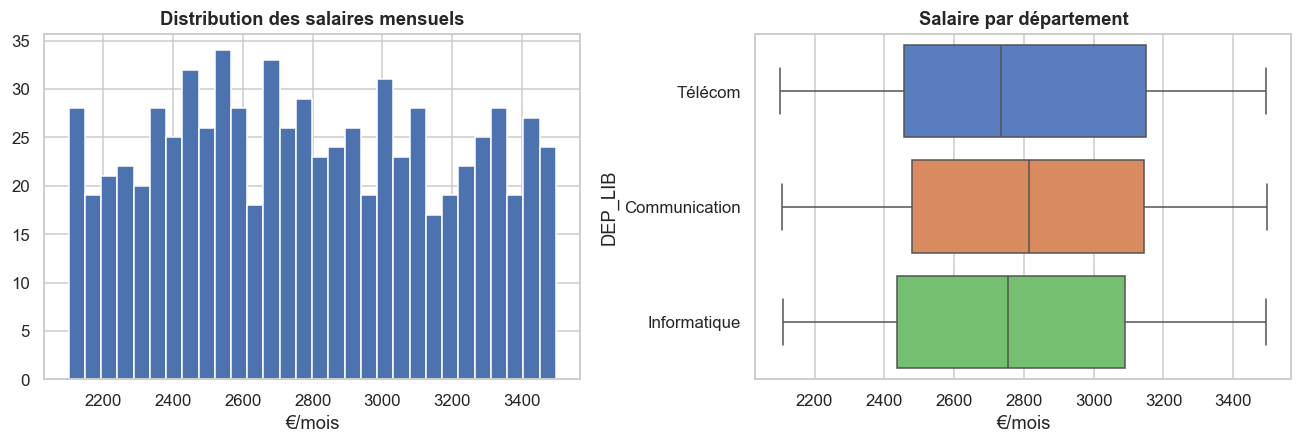

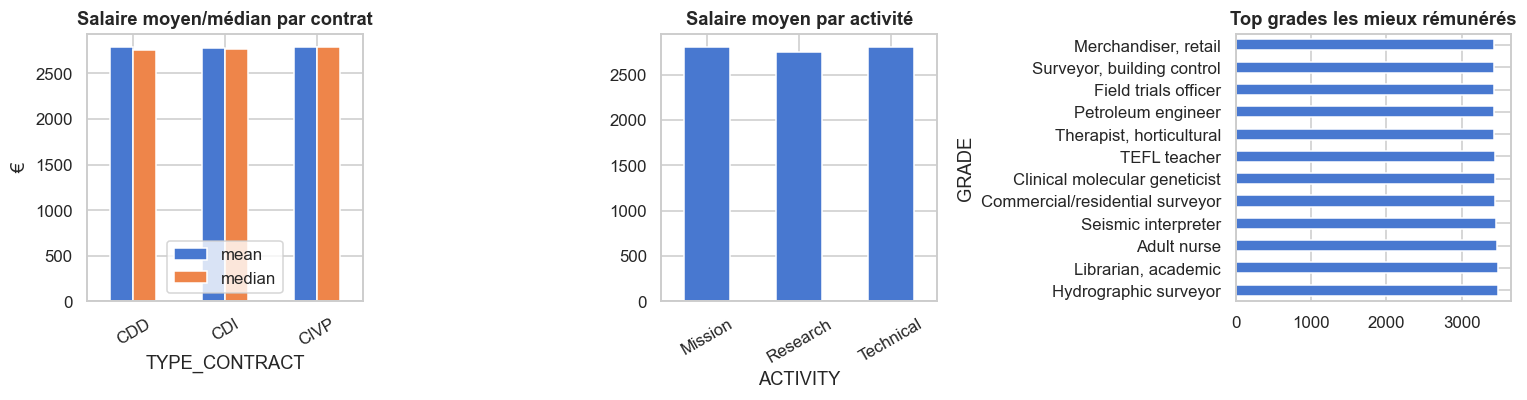


=== ÉCART DE SALAIRE H/F ===
          mean  median
GENDER                
F       2792.0  2765.0
M       2789.0  2771.0
Pay-gap médian : 0.2 % | Pay-gap moyen : -0.1 %


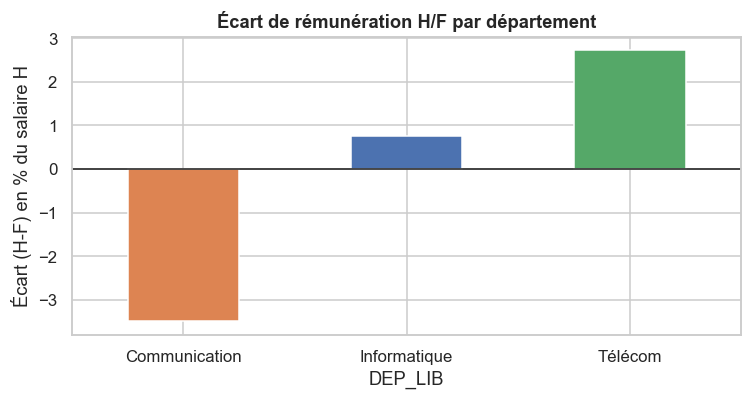


=== COÛT MENSUEL ESTIMÉ (unités monétaires : devise non précisée) ===
  Hypothèse : HOURS et extra_hour sont des volumes mensuels (à confirmer)
  Salaires permanents techniques : 2,075,982
  Salaires administratifs (1279) : 3,765,752
  Vacataires techniques (717) : 2,629,935 (heures × 35)
  Heures sup admin (130,001 h) : 2,860,022 (heures × 22)
  TOTAL : 11,331,691
[  16.6s] segment 3 — OM2 OK


In [4]:
if should(3):
    emp, adm = DATA["emp"], DATA["adm"]
    sal = emp.dropna(subset=["SALARY"]).copy()

    print(f"=== SALAIRES — stats ({len(sal)} permanents techniques ; "
          f"les vacataires sont payés à l'heure) ===")
    print(sal.SALARY.describe().round(0).to_string())

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    sal.SALARY.hist(bins=30, ax=axes[0], color="#4C72B0", edgecolor="white")
    axes[0].set_title("Distribution des salaires mensuels"); axes[0].set_xlabel("€/mois")
    sns.boxplot(data=sal, x="SALARY", y="DEP_LIB", ax=axes[1], orient="h",
                hue="DEP_LIB", palette="muted", legend=False)
    axes[1].set_title("Salaire par département"); axes[1].set_xlabel("€/mois")
    plt.tight_layout(); plt.savefig("figures/fig03_salaires_distrib.png", bbox_inches="tight")
    plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
    sal.groupby("TYPE_CONTRACT")["SALARY"].agg(["mean", "median"]).round(0).plot(
        kind="bar", ax=axes[0], title="Salaire moyen/médian par contrat")
    axes[0].set_ylabel("€")
    sal.groupby("ACTIVITY")["SALARY"].mean().round(0).plot(
        kind="bar", ax=axes[1], title="Salaire moyen par activité")
    sal.groupby("GRADE")["SALARY"].mean().sort_values(ascending=False).head(12).plot(
        kind="barh", ax=axes[2], title="Top grades les mieux rémunérés")
    for ax in axes:
        ax.tick_params(axis="x", rotation=30 if ax in (axes[0], axes[1]) else 0)
    plt.tight_layout(); plt.savefig("figures/fig04_salaire_groupes.png", bbox_inches="tight")
    plt.show()

    gap = sal.groupby("GENDER")["SALARY"].agg(["mean", "median"])
    paygap_median = (gap.loc["M", "median"] - gap.loc["F", "median"]) / gap.loc["M", "median"] * 100
    paygap_mean = (gap.loc["M", "mean"] - gap.loc["F", "mean"]) / gap.loc["M", "mean"] * 100
    print("\n=== ÉCART DE SALAIRE H/F ===")
    print(gap.round(0).to_string())
    print(f"Pay-gap médian : {paygap_median:.1f} % | Pay-gap moyen : {paygap_mean:.1f} %")

    gap_dep = sal.groupby(["DEP_LIB", "GENDER"])["SALARY"].mean().unstack()
    gap_dep["gap%"] = (gap_dep["M"] - gap_dep["F"]) / gap_dep["M"] * 100
    fig, ax = plt.subplots(figsize=(7, 3.8))
    gap_dep["gap%"].plot(kind="bar", color=["#DD8452", "#4C72B0", "#55A868"], ax=ax)
    ax.axhline(0, color="k", lw=1)
    ax.set_ylabel("Écart (H-F) en % du salaire H"); ax.set_title("Écart de rémunération H/F par département")
    ax.tick_params(axis="x", rotation=0)
    plt.tight_layout(); plt.savefig("figures/fig05_paygap.png", bbox_inches="tight")
    plt.show()

    vac = emp.dropna(subset=["HOURS"])
    masse_perm = sal["SALARY"].sum()
    masse_adm = adm["SALARY"].sum()
    masse_vac = (vac["HOURS"] * RATE_VACATAIRE).sum()
    masse_adm_ot = adm["extra_hour"].sum() * RATE_OT_ADMIN
    msol = masse_perm + masse_adm + masse_vac + masse_adm_ot
    print("\n=== COÛT MENSUEL ESTIMÉ (unités monétaires : devise non précisée) ===")
    print("  Hypothèse : HOURS et extra_hour sont des volumes mensuels (à confirmer)")
    print(f"  Salaires permanents techniques : {masse_perm:,.0f}")
    print(f"  Salaires administratifs ({adm.SALARY.notna().sum()}) : {masse_adm:,.0f}")
    print(f"  Vacataires techniques ({len(vac)}) : {masse_vac:,.0f} (heures × 35)")
    print(f"  Heures sup admin ({adm.extra_hour.sum():,.0f} h) : {masse_adm_ot:,.0f} (heures × 22)")
    print(f"  TOTAL : {msol:,.0f}")
    _log("segment 3 — OM2 OK")

## 4. OM3 — Assiduité et temps réellement travaillé

**Interrogation métier :** les équipes sont-elles assidues ? Quelle est la charge réelle
(heures travaillées, retards, absences, heures sup) et y a-t-il des écarts entre pôles ?

**KPIs :** heures travaillées / jour moyen ; % de jours avec arrivée après 8h30 (retard) ;
jours d'absence vs jours ouvrés ; jours > 8 h (heures supplémentaires).

Pointages : tech 189799 lignes (worked null: 49), admin 83200 lignes (null: 0)


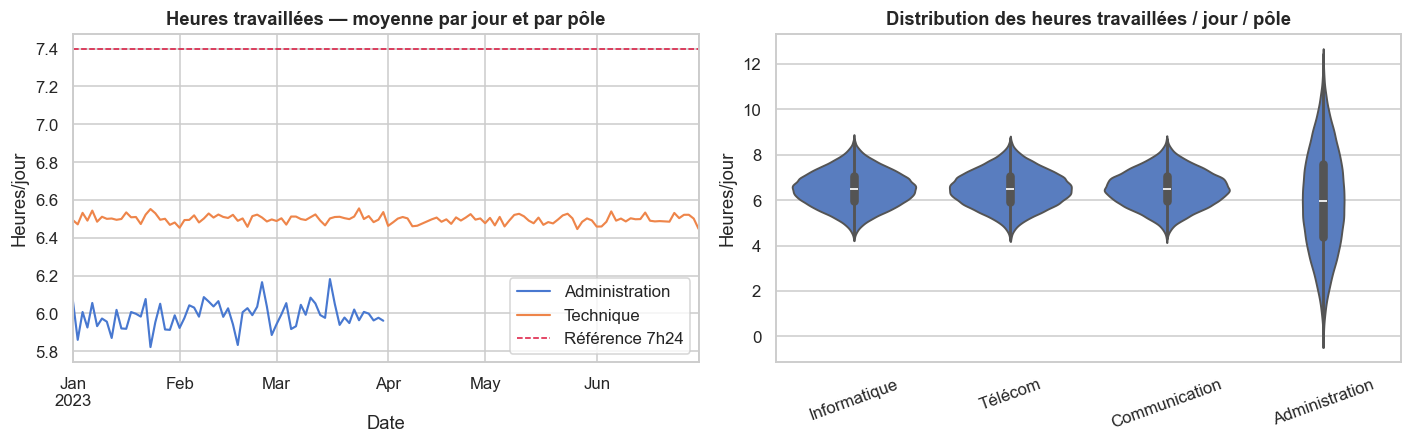


=== AGGRÉGAT / EMPLOYÉ (technique) ===
         n_days  mean_worked  late_pct    ot_pct
count  1460.000     1460.000  1460.000  1460.000
mean    129.999        6.498     0.491     0.021
std       0.026        0.068     0.044     0.013
min     129.000        6.268     0.315     0.000
25%     130.000        6.452     0.462     0.015
50%     130.000        6.502     0.492     0.023
75%     130.000        6.544     0.523     0.031
max     130.000        6.736     0.646     0.069

Jours ouvrés attendus : tech 130 | admin 65

=== PROFIL PAR DÉPARTEMENT ===
                employees  heures_jour  retard_pct  absences_moy  heures_sup_pct
DEP_LIB                                                                         
Administration       1280         5.99       49.41           0.0           19.58
Communication         511         6.50       48.84           0.0            2.05
Informatique          504         6.50       49.24           0.0            2.17
Télécom               441         6.5

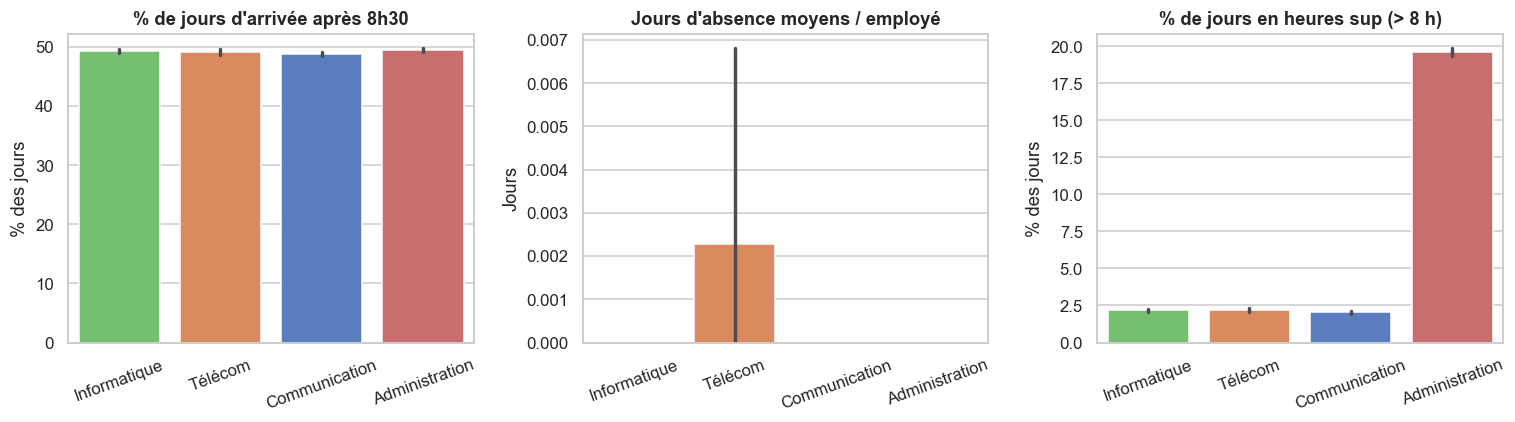

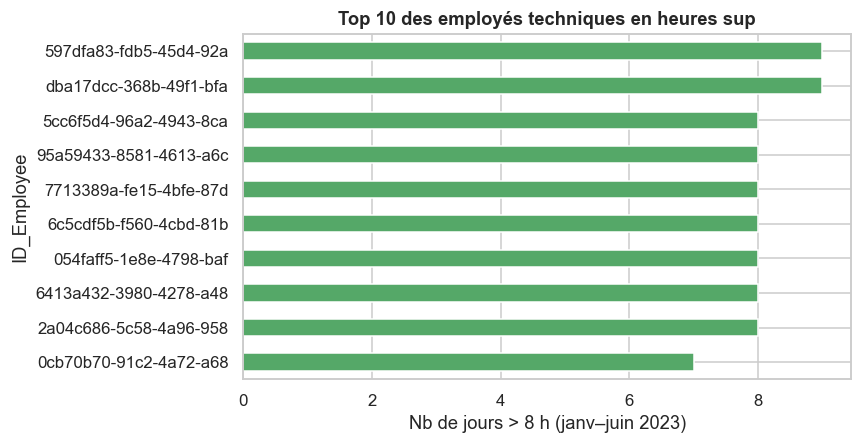


=== HEURES SUP TECHNIQUES ===
Total jours-employé > 8 h : 4,046
[  23.3s] segment 4 — OM3 OK


In [5]:
if should(4):
    emp, adm, att_p, att_a_p = DATA["emp"], DATA["adm"], DATA["att_p"], DATA["att_a_p"]

    att_p["DEP_LIB"] = att_p.ID_Employee.map(emp.set_index("ID_Employee").DEP_LIB)
    att_a_p["DEP_LIB"] = "Administration"
    print(f"Pointages : tech {len(att_p)} lignes (worked null: {att_p.worked.isna().sum()}), "
          f"admin {len(att_a_p)} lignes (null: {att_a_p.worked.isna().sum()})")

    att_all = pd.concat([att_p[["Date", "worked", "DEP_LIB"]].dropna(),
                         att_a_p[["Date", "worked", "DEP_LIB"]].dropna()])
    # Une courbe par pôle : les pointages admin s'arrêtent fin mars, une moyenne commune
    # créerait une fausse « hausse » en avril (effet de composition)
    att_all["POLE"] = np.where(att_all.DEP_LIB == "Administration", "Administration", "Technique")
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    att_all.groupby(["Date", "POLE"])["worked"].mean().unstack().plot(ax=axes[0], lw=1.4)
    axes[0].set_title("Heures travaillées — moyenne par jour et par pôle")
    axes[0].set_ylabel("Heures/jour")
    axes[0].axhline(7.4, color="crimson", ls="--", lw=1, label="Référence 7h24"); axes[0].legend()
    sns.violinplot(data=att_all, x="DEP_LIB", y="worked", ax=axes[1], cut=0,
                   order=DEP_ORDER_ALL)
    axes[1].set_title("Distribution des heures travaillées / jour / pôle")
    axes[1].set_ylabel("Heures/jour"); axes[1].set_xlabel("")
    axes[1].tick_params(axis="x", rotation=20)
    plt.tight_layout(); plt.savefig("figures/fig06_heures_travail.png", bbox_inches="tight")
    plt.show()

    def agg_emp(att_df):
        g = att_df.groupby("ID_Employee").agg(
            n_days=("Date", "nunique"), mean_worked=("worked", "mean"),
            n_late=("late", "sum"), late_pct=("late", "mean"),
            n_ot=("ot", "sum"), ot_pct=("ot", "mean"))
        return g

    g_emp = agg_emp(att_p); g_adm = agg_emp(att_a_p)
    g_emp["DEP_LIB"] = g_emp.index.map(emp.set_index("ID_Employee").DEP_LIB)
    g_adm["DEP_LIB"] = "Administration"
    g_all = pd.concat([g_emp, g_adm])

    exp_tech = pd.bdate_range("2023-01-02", "2023-06-30").shape[0]
    exp_adm = pd.bdate_range("2023-01-02", "2023-03-31").shape[0]
    g_emp["absent_days"] = exp_tech - g_emp["n_days"]
    g_adm["absent_days"] = exp_adm - g_adm["n_days"]
    g_all["absent_days"] = pd.concat([g_emp["absent_days"], g_adm["absent_days"]])
    g_all["late_pct"] = g_all["late_pct"] * 100
    g_all["ot_pct"] = g_all["ot_pct"] * 100

    print("\n=== AGGRÉGAT / EMPLOYÉ (technique) ===")
    print(g_emp[["n_days", "mean_worked", "late_pct", "ot_pct"]].describe().round(3).to_string())
    print(f"\nJours ouvrés attendus : tech {exp_tech} | admin {exp_adm}")

    prof = g_all.groupby("DEP_LIB").agg(
        employees=("mean_worked", "size"), heures_jour=("mean_worked", "mean"),
        retard_pct=("late_pct", "mean"), absences_moy=("absent_days", "mean"),
        heures_sup_pct=("ot_pct", "mean"))
    print("\n=== PROFIL PAR DÉPARTEMENT ===")
    print(prof.round(2).to_string())
    prof.round(2).to_csv("figures/profil_departement.csv", encoding="utf-8-sig")

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, y, t, lab in [
            (axes[0], "late_pct", "% de jours d'arrivée après 8h30", "% des jours"),
            (axes[1], "absent_days", "Jours d'absence moyens / employé", "Jours"),
            (axes[2], "ot_pct", "% de jours en heures sup (> 8 h)", "% des jours")]:
        sns.barplot(data=g_all, x="DEP_LIB", y=y, ax=ax, err_kws={"color": ".3"},
                    hue="DEP_LIB", palette="muted", order=DEP_ORDER_ALL, legend=False)
        ax.set_title(t); ax.set_ylabel(lab); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)
    plt.tight_layout(); plt.savefig("figures/fig07_assiduite_dept.png", bbox_inches="tight")
    plt.show()

    top_ot = g_emp.nlargest(10, "n_ot").sort_values("n_ot")
    fig, ax = plt.subplots(figsize=(8, 4.2))
    top_ot["n_ot"].plot(kind="barh", ax=ax, color="#55A868")
    ax.set_xlabel("Nb de jours > 8 h (janv–juin 2023)")
    ax.set_title("Top 10 des employés techniques en heures sup")
    ax.set_yticks(range(len(top_ot)))
    ax.set_yticklabels([str(i)[:22] for i in top_ot.index])
    plt.tight_layout(); plt.savefig("figures/fig08_top_ot.png", bbox_inches="tight")
    plt.show()

    ot_tech = int(g_emp["n_ot"].sum())
    print(f"\n=== HEURES SUP TECHNIQUES ===")
    print(f"Total jours-employé > 8 h : {ot_tech:,}")
    _log("segment 4 — OM3 OK")

## 5. OM4 — Formation et montée en compétences

**Interrogation métier :** le catalogue Coursera est-il exploité ? Quelles formations
prioriser pour la montée en compétences des pôles techniques ?

**KPIs :** % d'employés formés ; nb formations / employé ; difficultés suivies ;
top formations & universités ; compétences du catalogue les plus sollicitées.

Employés formés : 1441 / 1461 (99 %) | inscriptions: 18685

=== NB FORMATIONS / EMPLOYÉ ===
count    1441.0
mean       13.0
std         7.3
min         1.0
25%         6.0
50%        13.0
75%        19.0
max        25.0


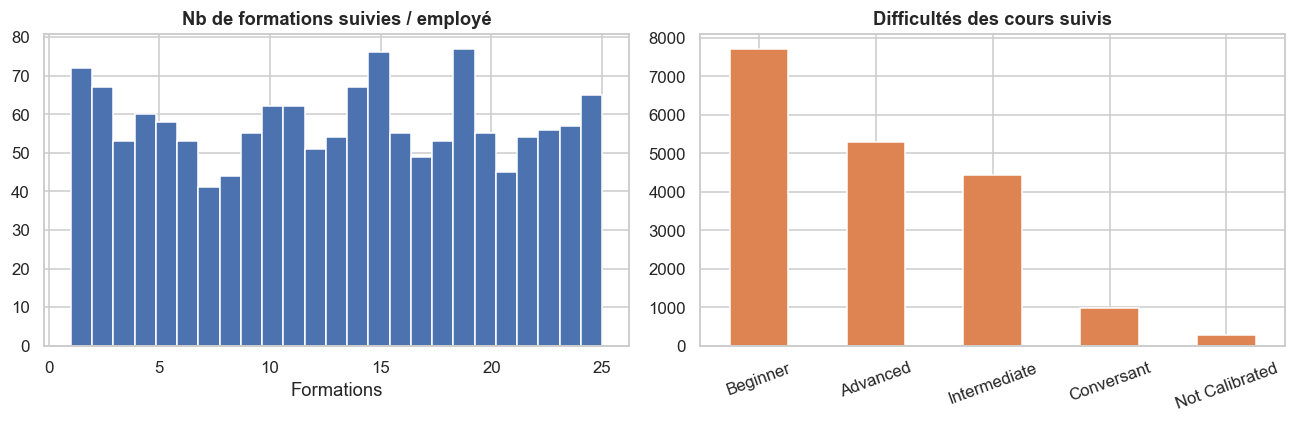


=== TOP 12 FORMATIONS / TOP 8 UNIVERSITÉS ===
Course Name
Google Cloud Platform Fundamentals: Core Infrastructure     46
Python for Data Science and AI                              27
Introduction to Artificial Intelligence (AI)                27
The Art of Music Production                                 27
Databases and SQL for Data Science                          25
Reliable Google Cloud Infrastructure: Design and Process    22
Exploratory Data Analysis                                   20
Data Visualization with Python                              20
Effective Problem-Solving and Decision-Making               19
Pro Tools Basics                                            18
Data Analysis with Python                                   17
Network Security & Database Vulnerabilities                 17
University
Coursera Project Network                      2956
University of Illinois at Urbana-Champaign     744
Johns Hopkins University                       603
University of Colorad

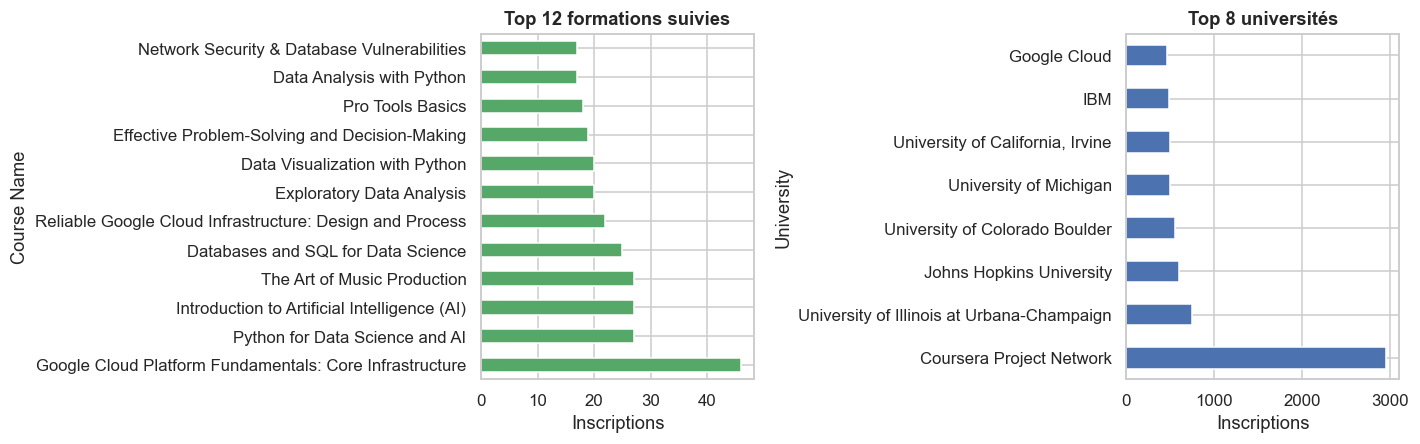


=== DIFFICULTÉ DES COURS SUIVIS PAR DÉPARTEMENT ===
Difficulty Level  Advanced  Beginner  Conversant  Intermediate  Not Calibrated  total
DEP_LIB                                                                              
Communication         1835      2732         379          1582              96   6624
Informatique          1787      2580         311          1451              87   6216
Télécom               1644      2384         284          1385              81   5778

=== COMPÉTENCES (niveau Beginner) LES PLUS SUIVIES ===
  management                          3010
  project                             2335
  analysis                            2276
  business                            2268
  programming                         2157
  learning                            1866
  data                                1855
  data-science                        1506

=== % EMPLOYÉS FORMÉS PAR DÉPARTEMENT ===
DEP_LIB
Communication    98.4
Informatique     99.2
Télécom          98.2


In [6]:
if should(5):
    emp, cour = DATA["emp"], DATA["cour"]
    emp_train = emp.dropna(subset=["ID_TRAINING"]).copy()
    emp_train["train_ids"] = emp_train["ID_TRAINING"].map(ast.literal_eval)
    cour_rat = (cour.dropna(subset=["course_id"]).drop(columns=["course_id"])
                .set_index(cour.dropna(subset=["course_id"])["course_id"].astype(int)))

    rows = []
    for _, r in emp_train.iterrows():
        for cid in r["train_ids"]:
            rows.append({"ID_Employee": r["ID_Employee"], "DEP_LIB": r["DEP_LIB"],
                         "course_id": int(cid)})
    u5 = pd.DataFrame(rows).merge(cour_rat.reset_index(), on="course_id", how="left")

    print(f"Employés formés : {emp_train.ID_Employee.nunique()} / {len(emp)} "
          f"({emp_train.ID_Employee.nunique()/len(emp)*100:.0f} %) | inscriptions: {len(u5)}")
    per_emp = u5.groupby("ID_Employee").size().rename("n_formations")
    print("\n=== NB FORMATIONS / EMPLOYÉ ===")
    print(per_emp.describe().round(1).to_string())

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    per_emp.hist(bins=25, ax=axes[0], color="#4C72B0", edgecolor="white")
    axes[0].set_title("Nb de formations suivies / employé"); axes[0].set_xlabel("Formations")
    u5["Difficulty Level"].value_counts().plot(kind="bar", ax=axes[1], color="#DD8452")
    axes[1].set_title("Difficultés des cours suivis"); axes[1].set_xlabel("")
    axes[1].tick_params(axis="x", rotation=20)
    plt.tight_layout(); plt.savefig("figures/fig09_formation_couverture.png", bbox_inches="tight")
    plt.show()

    print("\n=== TOP 12 FORMATIONS / TOP 8 UNIVERSITÉS ===")
    print(u5["Course Name"].value_counts().head(12).to_string())
    print(u5["University"].value_counts().head(8).to_string())

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    u5["Course Name"].value_counts().head(12).plot(kind="barh", ax=axes[0], color="#55A868")
    axes[0].set_title("Top 12 formations suivies"); axes[0].set_xlabel("Inscriptions")
    u5["University"].value_counts().head(8).plot(kind="barh", ax=axes[1], color="#4C72B0")
    axes[1].set_title("Top 8 universités"); axes[1].set_xlabel("Inscriptions")
    plt.tight_layout(); plt.savefig("figures/fig10_top_formations.png", bbox_inches="tight")
    plt.show()

    dia = pd.crosstab(u5["DEP_LIB"], u5["Difficulty Level"])
    dia["total"] = dia.sum(axis=1)
    print("\n=== DIFFICULTÉ DES COURS SUIVIS PAR DÉPARTEMENT ===")
    print(dia.round(0).to_string())

    from collections import Counter
    STOPWORDS = {"and", "of", "the", "for", "to", "in", "with", "a", "&", "-"}

    def top_skills(difficulty="Beginner"):
        cnt = Counter()
        for s in u5[u5["Difficulty Level"] == difficulty]["Skills"].dropna():
            for sk in str(s).replace(",", " ").split():
                if sk.strip() and sk.strip().lower() not in STOPWORDS:
                    cnt[sk.strip().lower()] += 1
        return cnt.most_common(8)

    print("\n=== COMPÉTENCES (niveau Beginner) LES PLUS SUIVIES ===")
    for sk, v in top_skills("Beginner"):
        print(f"  {sk:35s} {v}")

    cov_dep = (u5.groupby("DEP_LIB")["ID_Employee"].nunique() /
               emp.groupby("DEP_LIB")["ID_Employee"].nunique() * 100)
    print("\n=== % EMPLOYÉS FORMÉS PAR DÉPARTEMENT ===")
    print(cov_dep.round(1).to_string())
    _log("segment 5 — OM4 OK")

## 6. OM5 — Congés et risque de départ

**Interrogation métier :** la consommation des congés est-elle maîtrisée ? Certains profils
concentrent-ils des signaux de risque (fin de CDD, congés importants, solde faible) ?

**KPIs :** taux de consommation (consommé / solde total) ; types de congé ; solde moyen par
département ; part des fins de contrat avant fin 2023.


=== FINS DE CONTRAT ===
Dates de fin <= fin 2023 : 1013
  dont déjà échues avant 2023 (dates non fiables) : 663
  dont échéances réelles en 2023 : 350 (12.8 % de l'effectif)


DEP_LIB         TYPE_CONTRACT
Administration  CDD              64
                CDI              75
                CIVP             69
Communication   CDD              20
                CDI              22
                CIVP             18
Informatique    CDD              18
                CDI              14
                CIVP              8
Télécom         CDD              17
                CDI              12
                CIVP             13
=== CONGÉS — stats globales (jours) ===
       LEAVE_CONSUMED  LEAVE_BALANCE  solde_total
count          2734.0         2734.0       2734.0
mean             15.1           14.8         30.0
std               8.8            8.9         12.5
min               0.0            0.0          0.0
25%               7.6            7.0         21.0
50%              15.0           15.0         30.0
75%              23.0           22.3         38.8
max              30.0           30.0         59.7


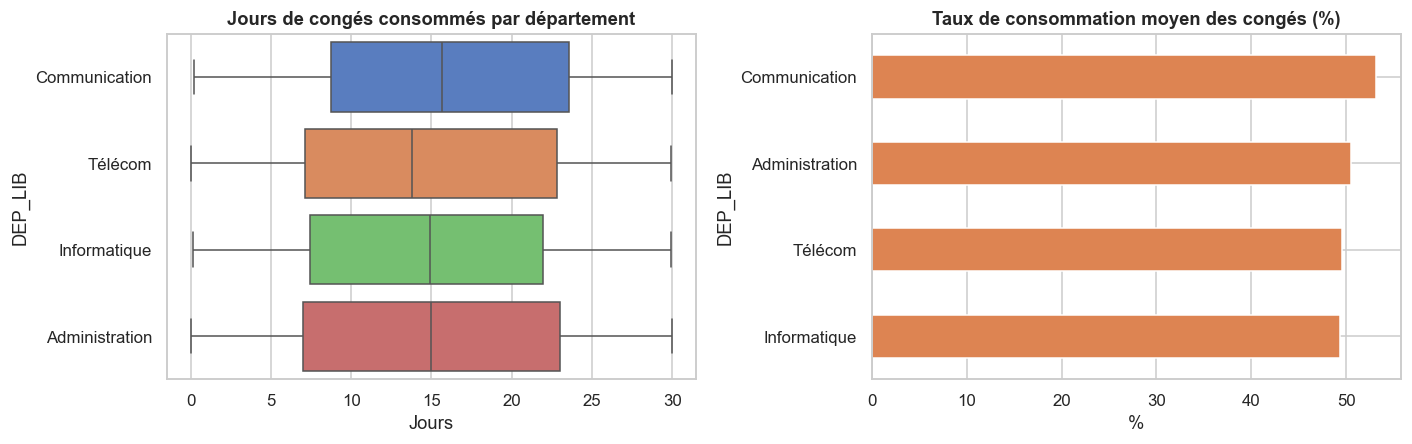


=== TYPES DE CONGÉ (dernier congé, libellés normalisés) ===
LAST_LEAVE_TYPE
sans_solde    716
mission       696
ordinary      674
sick          648


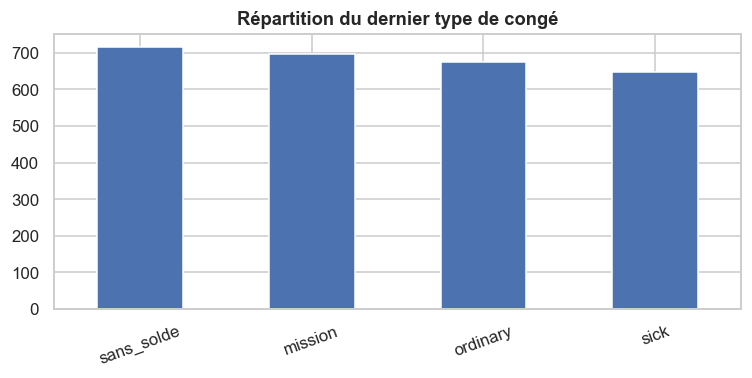


=== CONGÉ CONSOMMÉ PAR CONTRAT (moyenne) ===
               LEAVE_CONSUMED  LEAVE_BALANCE
TYPE_CONTRACT                               
CDD                      15.1           14.8
CDI                      15.0           15.2
CIVP                     15.1           14.6

=== CORRÉLATIONS (congés / ancienneté) ===
                LEAVE_CONSUMED  LEAVE_BALANCE  TENURE  taux_consom
LEAVE_CONSUMED            1.00          -0.00   -0.01         0.65
LEAVE_BALANCE            -0.00           1.00   -0.05        -0.66
TENURE                   -0.01          -0.05    1.00         0.02
taux_consom               0.65          -0.66    0.02         1.00
[  27.2s] segment 6 — OM5 OK


In [7]:
if should(6):
    emp, adm = DATA["emp"], DATA["adm"]
    emp_c = emp.rename(columns={"LEAVE_TYPE": "LAST_LEAVE_TYPE"})
    eff = pd.concat([
        emp_c[["ID_Employee", "DEP_LIB", "TYPE_CONTRACT", "LEAVE_CONSUMED", "LEAVE_BALANCE",
               "LAST_LEAVE_TYPE", "CONTRACT_END", "TENURE"]],
        adm[["ID_Employee", "DEP_LIB", "TYPE_CONTRACT", "LEAVE_CONSUMED", "LEAVE_BALANCE",
             "LAST_LEAVE_TYPE", "CONTRACT_END", "TENURE"]]], ignore_index=True)
    eff["LEAVE_CONSUMED"] = pd.to_numeric(eff["LEAVE_CONSUMED"], errors="coerce")
    eff["LEAVE_BALANCE"] = pd.to_numeric(eff["LEAVE_BALANCE"], errors="coerce")
    # Risque de départ calculé sur l'effectif complet (avant filtre congés)
    eff["CONTRACT_END"] = pd.to_datetime(eff["CONTRACT_END"], errors="coerce")
    n_effectif = eff["ID_Employee"].nunique()
    fin = eff["CONTRACT_END"]
    risk = eff[fin <= "2023-12-31"]
    deja_echus = eff[fin < "2023-01-01"]      # incohérent : ces employés pointent en 2023
    echeances_2023 = eff[fin.between("2023-01-01", "2023-12-31")]
    print("\n=== FINS DE CONTRAT ===")
    print(f"Dates de fin <= fin 2023 : {len(risk)}")
    print(f"  dont déjà échues avant 2023 (dates non fiables) : {len(deja_echus)}")
    print(f"  dont échéances réelles en 2023 : {len(echeances_2023)} "
          f"({len(echeances_2023)/n_effectif*100:.1f} % de l'effectif)")
    print(echeances_2023.groupby(["DEP_LIB", "TYPE_CONTRACT"]).size().to_string())

    eff = eff.dropna(subset=["LEAVE_CONSUMED", "LEAVE_BALANCE"])
    eff["solde_total"] = eff["LEAVE_CONSUMED"] + eff["LEAVE_BALANCE"]
    eff["taux_consom"] = eff.LEAVE_CONSUMED / eff.solde_total * 100

    print("=== CONGÉS — stats globales (jours) ===")
    print(eff[["LEAVE_CONSUMED", "LEAVE_BALANCE", "solde_total"]].describe().round(1).to_string())

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    sns.boxplot(data=eff, x="LEAVE_CONSUMED", y="DEP_LIB", orient="h", hue="DEP_LIB",
                palette="muted", legend=False, ax=axes[0])
    axes[0].set_title("Jours de congés consommés par département"); axes[0].set_xlabel("Jours")
    eff.groupby("DEP_LIB")["taux_consom"].mean().sort_values().plot(
        kind="barh", ax=axes[1], color="#DD8452")
    axes[1].set_title("Taux de consommation moyen des congés (%)"); axes[1].set_xlabel("%")
    plt.tight_layout(); plt.savefig("figures/fig11_conges_dept.png", bbox_inches="tight")
    plt.show()

    print("\n=== TYPES DE CONGÉ (dernier congé, libellés normalisés) ===")
    print(eff["LAST_LEAVE_TYPE"].value_counts().to_string())
    fig, ax = plt.subplots(figsize=(7, 3.6))
    eff["LAST_LEAVE_TYPE"].value_counts().plot(kind="bar", ax=ax, color="#4C72B0")
    ax.set_title("Répartition du dernier type de congé"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    plt.tight_layout(); plt.savefig("figures/fig12_types_conge.png", bbox_inches="tight")
    plt.show()

    print("\n=== CONGÉ CONSOMMÉ PAR CONTRAT (moyenne) ===")
    print(eff.groupby("TYPE_CONTRACT")[["LEAVE_CONSUMED", "LEAVE_BALANCE"]].mean().round(1).to_string())

    c = eff[["LEAVE_CONSUMED", "LEAVE_BALANCE", "TENURE", "taux_consom"]].corr().round(2)
    print("\n=== CORRÉLATIONS (congés / ancienneté) ===")
    print(c.to_string())
    _log("segment 6 — OM5 OK")

## 7. Synthèse — tableau de bord des KPI et recommandations

Chaque objectif métier est ramené à quelques indicateurs chiffrés.

In [8]:
if should(7):
    emp, adm = DATA["emp"], DATA["adm"]
    sal = emp.dropna(subset=["SALARY"])
    vac = emp.dropna(subset=["HOURS"])

    # KPI synthétiques (valeurs issues des étapes précédentes, recalculées ici)
    kpis = {
        "OM1 — Effectif (technique + admin)": int(len(emp) + len(adm)),
        "OM1 — Part contrats courts (CDD+CIVP)": f"{emp.TYPE_CONTRACT.isin(['CDD', 'CIVP']).mean()*100:.0f} %",
        "OM2 — Salaire médian (technique)": f"{sal.SALARY.median():,.0f} €/mois",
        "OM3 — Heures travaillées/jour (tech)": f"{DATA['att_p'].worked.mean():.2f} h",
        "OM3 — Heures travaillées/jour (admin)": f"{DATA['att_a_p'].worked.mean():.2f} h",
        "OM3 — Retards >8h30 (% jours tech/admin)": (
            f"{DATA['att_p'].late.mean()*100:.0f} % / {DATA['att_a_p'].late.mean()*100:.0f} %"),
        "OM4 — Employés formés": f"{emp.dropna(subset=['ID_TRAINING']).ID_Employee.nunique()/len(emp)*100:.0f} %",
        "OM5 — Congés consommés / employé": f"{round(float(emp.LEAVE_CONSUMED.mean()), 1)} j",
    }
    k = pd.DataFrame({"Indicateur": list(kpis), "Valeur": list(kpis.values())})
    print("=" * 88)
    print("TABLEAU DE BORD — KPI PAR OBJECTIF MÉTIER (extrait)")
    print("=" * 88)
    print(k.to_string(index=False))
    k.to_csv("figures/kpi_business.csv", index=False, encoding="utf-8-sig")

    print("\n" + "=" * 88)
    print("RECOMMANDATIONS (résumé)")
    print("=" * 88)
    print("""
1. OM1 : Télécom au-dessus de sa capacité, Communication sous-utilisée -> rééquilibrer ;
   l'Administration dépasse très largement son référentiel -> réviser ce référentiel.
2. OM2 : écart H/F quasi nul ; les salaires absents des vacataires sont structurels (paie à
   l'heure) -> faire valider la période de HOURS / extra_hour et la devise.
3. OM3 : taux de retard identique dans tous les pôles ; l'Administration concentre les jours
   de plus de 8 h et des horaires très dispersés -> lisser sa charge.
4. OM4 : couverture quasi totale mais sans fil thématique -> bâtir des parcours par métier.
5. OM5 : fiabiliser les dates de fin de contrat (contrats déjà échus, CDI datés) avant de
   piloter les échéances 2023.
""")
    _log("segment 7 — synthèse OK, FIN")
    print("FIN DE L'EDA")

TABLEAU DE BORD — KPI PAR OBJECTIF MÉTIER (extrait)
                              Indicateur       Valeur
      OM1 — Effectif (technique + admin)         2740
   OM1 — Part contrats courts (CDD+CIVP)         67 %
        OM2 — Salaire médian (technique) 2,765 €/mois
    OM3 — Heures travaillées/jour (tech)       6.50 h
   OM3 — Heures travaillées/jour (admin)       5.99 h
OM3 — Retards >8h30 (% jours tech/admin)  49 % / 49 %
                   OM4 — Employés formés         99 %
        OM5 — Congés consommés / employé       15.1 j

RECOMMANDATIONS (résumé)

1. OM1 : Télécom au-dessus de sa capacité, Communication sous-utilisée -> rééquilibrer ;
   l'Administration dépasse très largement son référentiel -> réviser ce référentiel.
2. OM2 : écart H/F quasi nul ; les salaires absents des vacataires sont structurels (paie à
   l'heure) -> faire valider la période de HOURS / extra_hour et la devise.
3. OM3 : taux de retard identique dans tous les pôles ; l'Administration concentre les jours

FIN DE L'EDA
